<a href="https://colab.research.google.com/github/SAMBOAH95/Machine-Learning-Projects/blob/main/Task2-Customer-Segmentation/Customer_Segmentation_KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

folder_path = '/content/drive/MyDrive/Elevo/Task2_Level1'


os.listdir(folder_path)

['Customer_Segmentation_KMeans.ipynb', 'Mall_Customers.csv']

In [5]:
file_path = folder_path + '/Mall_Customers.csv'

df = pd.read_csv(file_path)

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate records:
0


In [8]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


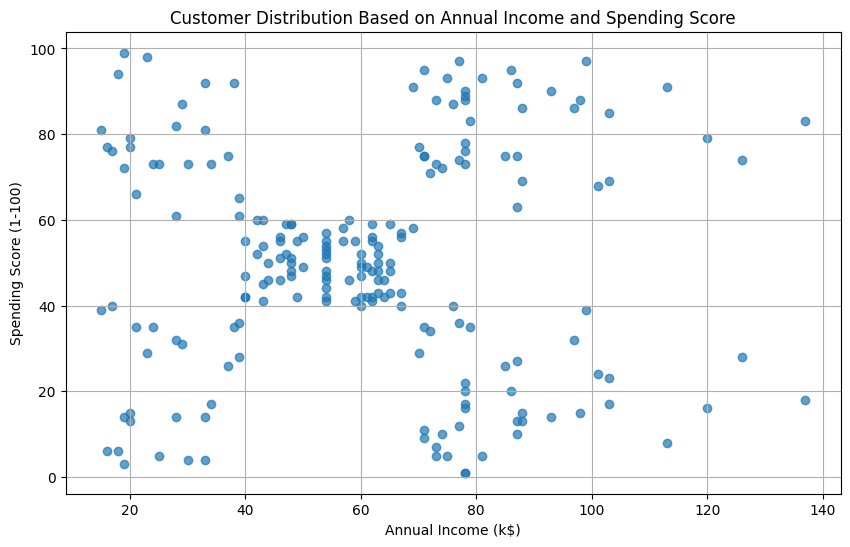

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    alpha=0.7
)

plt.title('Customer Distribution Based on Annual Income and Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.grid(True)
plt.show()

In [10]:
# Select the features for customer segmentation

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Display the first five records
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [11]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Transform the selected features
X_scaled = scaler.fit_transform(X)

# Convert scaled data into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Display the first five scaled records
X_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


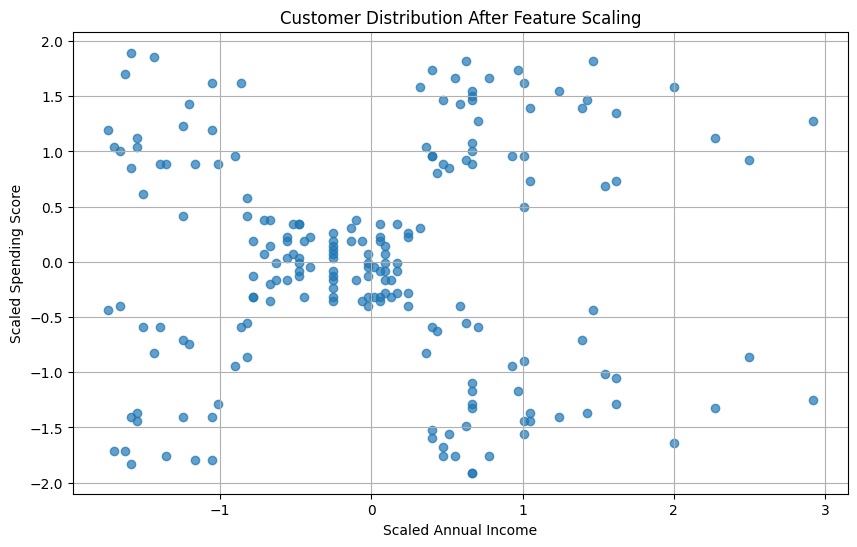

In [12]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled['Annual Income (k$)'],
    X_scaled['Spending Score (1-100)'],
    alpha=0.7
)

plt.title('Customer Distribution After Feature Scaling')
plt.xlabel('Scaled Annual Income')
plt.ylabel('Scaled Spending Score')

plt.grid(True)
plt.show()

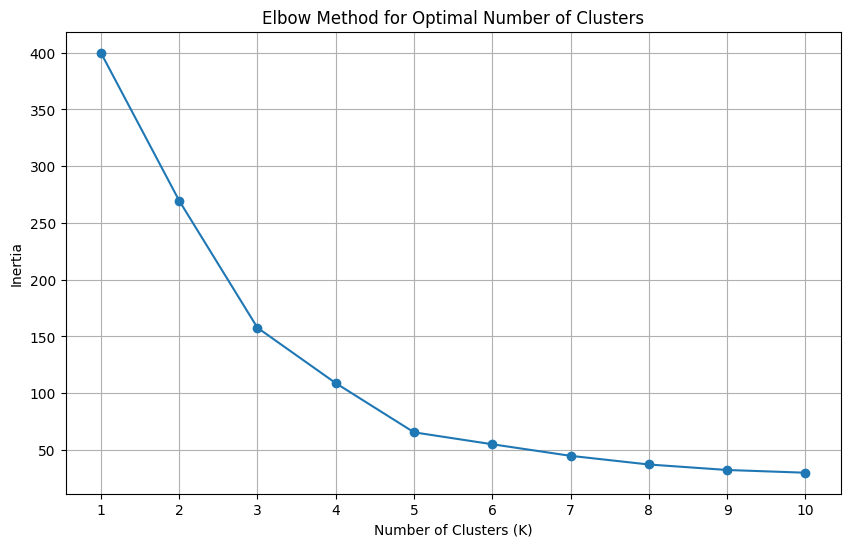

In [13]:
from sklearn.cluster import KMeans

# Store the inertia values
inertia = []

# Test different numbers of clusters
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [14]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, cluster_labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3213
K = 3, Silhouette Score = 0.4666
K = 4, Silhouette Score = 0.4939
K = 5, Silhouette Score = 0.5547
K = 6, Silhouette Score = 0.5399
K = 7, Silhouette Score = 0.5281
K = 8, Silhouette Score = 0.4552
K = 9, Silhouette Score = 0.4571
K = 10, Silhouette Score = 0.4432


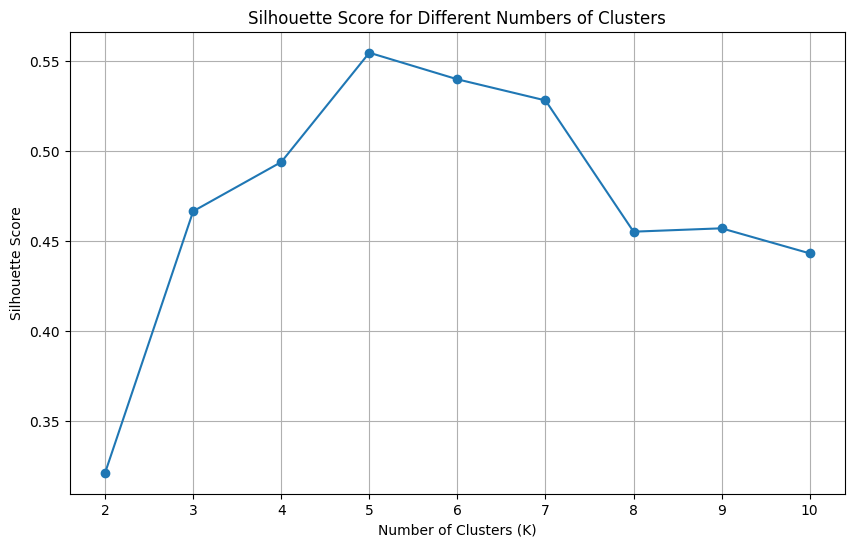

In [15]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score for Different Numbers of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [16]:
# Create the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Train the model and assign cluster labels
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df['Cluster'] = cluster_labels

# Display the first five records
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [17]:
# Count customers in each cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [18]:
# Calculate average characteristics of each cluster
cluster_analysis = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean()

print("Average Income and Spending Score by Cluster:")
print(cluster_analysis.round(2))

Average Income and Spending Score by Cluster:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91


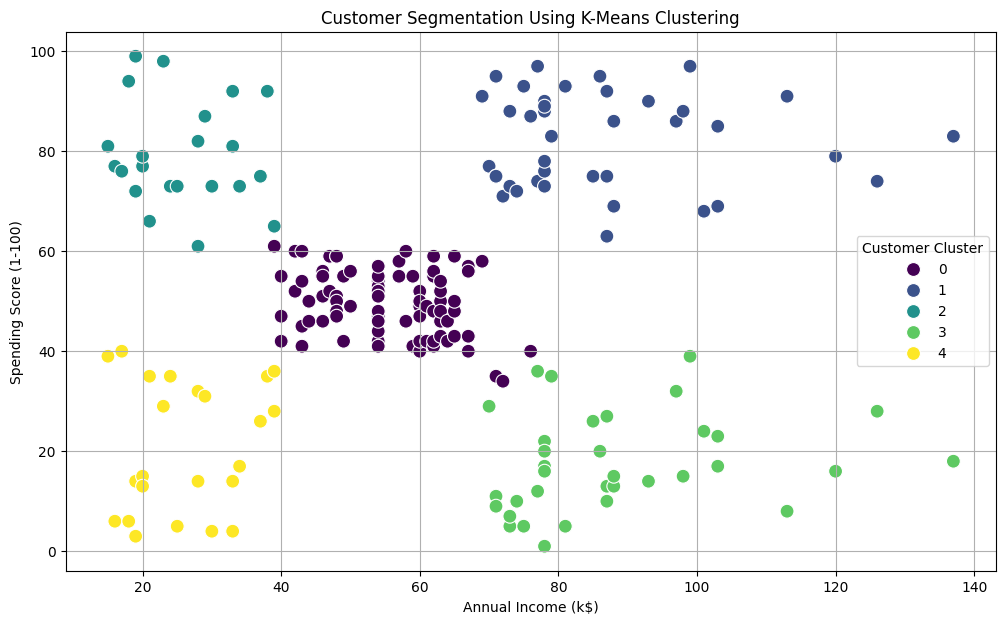

In [19]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title('Customer Segmentation Using K-Means Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.legend(title='Customer Cluster')
plt.grid(True)

plt.show()

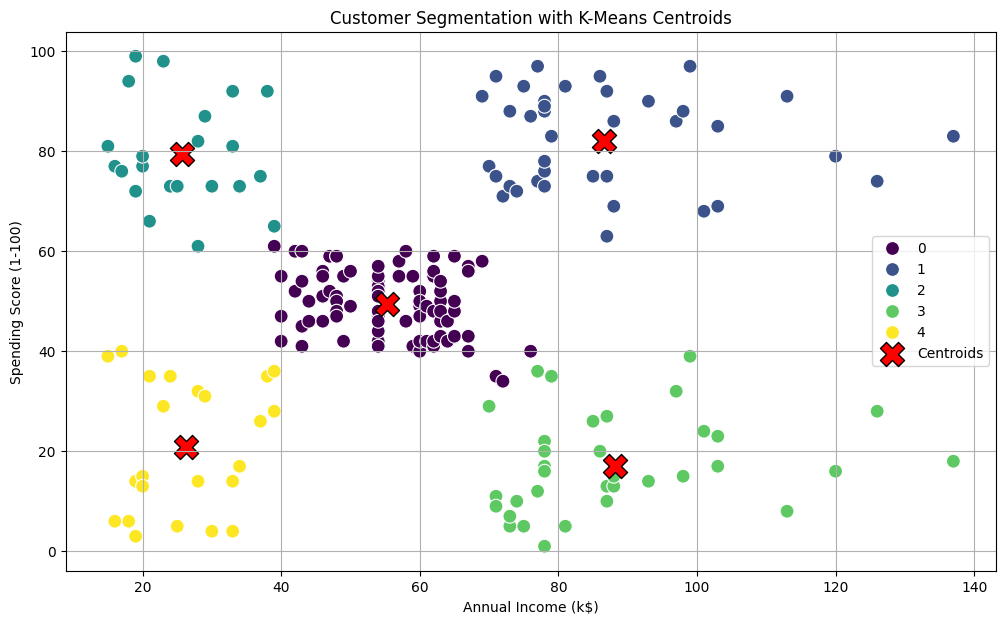

In [20]:
# Get the cluster centroids
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

# Plot the centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=300,
    color='red',
    edgecolor='black',
    label='Centroids'
)

plt.title('Customer Segmentation with K-Means Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.legend()
plt.grid(True)
plt.show()

In [21]:
from sklearn.metrics import silhouette_score

# Calculate final clustering performance
final_silhouette = silhouette_score(X_scaled, cluster_labels)

final_inertia = kmeans.inertia_

print("Final K-Means Model Evaluation")
print("--------------------------------")
print(f"Number of clusters: {kmeans.n_clusters}")
print(f"Silhouette Score: {final_silhouette:.4f}")
print(f"Inertia: {final_inertia:.4f}")
print(f"Total customers: {len(df)}")

Final K-Means Model Evaluation
--------------------------------
Number of clusters: 5
Silhouette Score: 0.5547
Inertia: 65.5684
Total customers: 200


In [22]:
# Save the dataset with cluster assignments
output_path = folder_path + '/Customer_Segmentation_Results.csv'

df.to_csv(output_path, index=False)

print("Customer segmentation results saved successfully!")
print(output_path)

Customer segmentation results saved successfully!
/content/drive/MyDrive/Elevo/Task2_Level1/Customer_Segmentation_Results.csv


In [23]:
import os
import pandas as pd

output_path = '/content/drive/MyDrive/Elevo/Task2_Level1/Customer_Segmentation_Results.csv'

print("File exists:", os.path.exists(output_path))

results_df = pd.read_csv(output_path)

print("Dataset shape:", results_df.shape)

results_df.head()

File exists: True
Dataset shape: (200, 6)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [24]:
# Calculate average spending score for each cluster
average_spending = df.groupby('Cluster')[
    'Spending Score (1-100)'
].mean().sort_index()

print("Average Spending Score by Customer Cluster:")
print(average_spending.round(2))

Average Spending Score by Customer Cluster:
Cluster
0    49.52
1    82.13
2    79.36
3    17.11
4    20.91
Name: Spending Score (1-100), dtype: float64


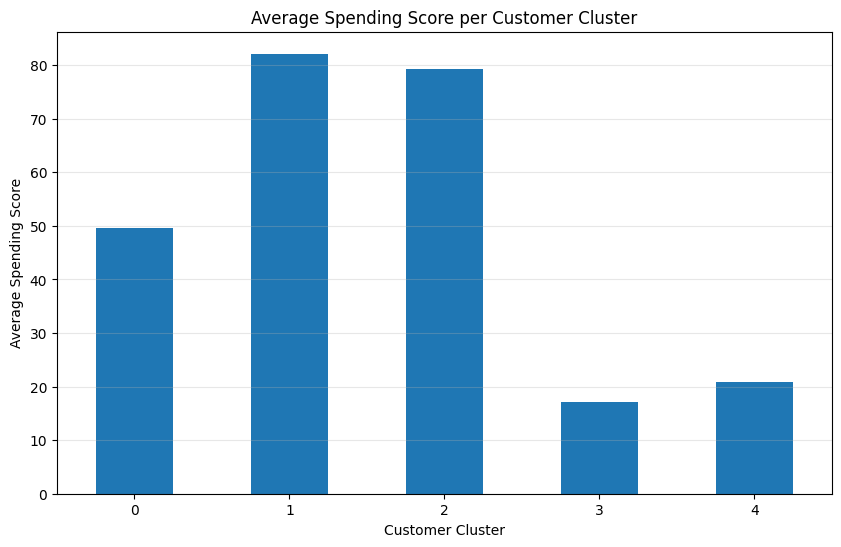

In [25]:
plt.figure(figsize=(10, 6))

average_spending.plot(
    kind='bar',
    title='Average Spending Score per Customer Cluster'
)

plt.xlabel('Customer Cluster')
plt.ylabel('Average Spending Score')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [26]:
from sklearn.cluster import DBSCAN

# Create the DBSCAN model
dbscan = DBSCAN(eps=0.3, min_samples=5)

# Fit the model and predict cluster labels
dbscan_labels = dbscan.fit_predict(X_scaled)

# Store DBSCAN results separately
df['DBSCAN_Cluster'] = dbscan_labels

# Display the number of customers in each DBSCAN group
print("DBSCAN Cluster Distribution:")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64


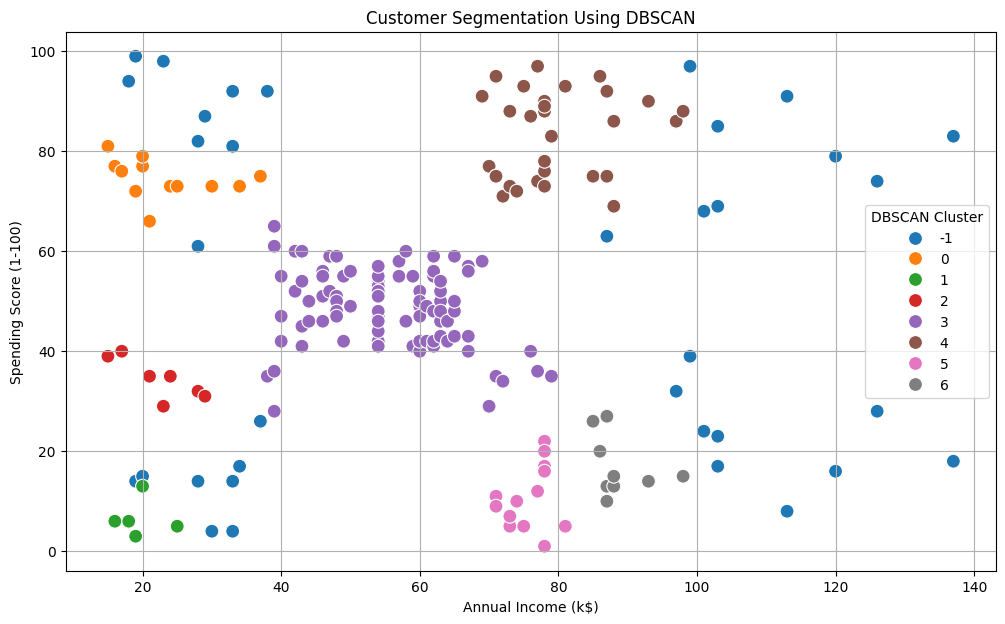

In [27]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='DBSCAN_Cluster',
    palette='tab10',
    s=100
)

plt.title('Customer Segmentation Using DBSCAN')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='DBSCAN Cluster')
plt.grid(True)

plt.show()

In [28]:
from sklearn.metrics import silhouette_score

# Exclude noise points
non_noise_mask = df['DBSCAN_Cluster'] != -1

# Select only customers assigned to clusters
X_dbscan = X_scaled[non_noise_mask]
labels_dbscan = df.loc[non_noise_mask, 'DBSCAN_Cluster']

# Count the actual clusters, excluding noise
number_of_clusters = labels_dbscan.nunique()

if number_of_clusters >= 2:
    dbscan_silhouette = silhouette_score(
        X_dbscan,
        labels_dbscan
    )

    print("DBSCAN Model Evaluation")
    print("-----------------------")
    print("Number of clusters:", number_of_clusters)
    print("Noise points:", (df['DBSCAN_Cluster'] == -1).sum())
    print("Silhouette Score:", round(dbscan_silhouette, 4))
else:
    print("Silhouette Score cannot be calculated.")

DBSCAN Model Evaluation
-----------------------
Number of clusters: 7
Noise points: 35
Silhouette Score: 0.5243


In [29]:
comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'DBSCAN'],
    'Number of Clusters': [5, 7],
    'Silhouette Score': [0.5547, 0.5243],
    'Noise Points': [0, 35]
})

print("CLUSTERING ALGORITHM COMPARISON")
print("--------------------------------")
print(comparison.to_string(index=False))

CLUSTERING ALGORITHM COMPARISON
--------------------------------
Algorithm  Number of Clusters  Silhouette Score  Noise Points
  K-Means                   5            0.5547             0
   DBSCAN                   7            0.5243            35
